In [3]:
import pandas as pd

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data, columns= cancer.feature_names)
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
lr_clf = LogisticRegression(solver= "liblinear")
knn_clf = KNeighborsClassifier(n_neighbors=8)

vo_clf = VotingClassifier(estimators=[("LR",lr_clf),("KNN", knn_clf)],voting="soft")

X_train,X_test,y_train,y_test = train_test_split(cancer.data , cancer.target, test_size= 0.2 , random_state= 156)

vo_clf.fit (X_train,y_train)
pred = vo_clf.predict(X_test)
print(accuracy_score(y_test,pred))

classifiers = [lr_clf, knn_clf]
for classifier in classifiers : 
    classifier.fit(X_train, y_train)
    pred = classifier.predict(X_test)
    print(classifier.__class__.__name__,accuracy_score(y_test, pred))



0.956140350877193
LogisticRegression 0.9473684210526315
KNeighborsClassifier 0.9385964912280702


c:\Users\Win11Pro\Documents\ML\.venv-machineLearning\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


In [5]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data = old_feature_name_df.groupby('column_name').cumcount(),
                                  columns = ['dup_cnt'])
    feature_dup_df = feature_dup_df.reset_index()
    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how = 'outer')
    new_feature_name_df['column_name'] = new_feature_name_df[['column_name', 'dup_cnt']].apply(lambda x: x[0] + '_' + str(x[1]) if x[1] > 0 else x[0], axis = 1)
    new_feature_name_df = new_feature_name_df.drop(['index'], axis = 1)
    return new_feature_name_df

In [6]:
import csv
import pandas as pd

ACTION_MAP = {
    "WALKING": 1,
    "WALKING_UPSTAIRS": 2,
    "WALKING_DOWNSTAIRS": 3,
    "SITTING": 4,
    "STANDING": 5,
    "LAYING": 6,
}

def get_human_dataset():
    train_file = "./human_activity_train.csv"
    test_file = "./human_activity_test.csv"

    with open('./human_activity_train.csv', encoding = 'utf-8') as f:
        header = next(csv.reader(f))
    feature_name_org = header[:-2]

    feature_name_df = pd.DataFrame({
        "column_index": range(1, len(feature_name_org) + 1),
        "column_name": feature_name_org
    })

    new_feature_name_df = get_new_feature_name_df(feature_name_df)
    feature_name = new_feature_name_df["column_name"].tolist()

    col_names = feature_name + ["subject", "action"]
    train_df = pd.read_csv(train_file, header=0, names=col_names)
    test_df = pd.read_csv(test_file, header=0, names=col_names)
    X_train = train_df[feature_name]
    X_test = test_df[feature_name]
    y_train = train_df[["action"]]
    y_test = test_df[["action"]]

    return X_train, X_test, y_train, y_test

In [7]:
X_train,X_test,y_train,y_test = get_human_dataset()
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(7352, 561)
(2947, 561)
(7352, 1)
(2947, 1)


In [8]:
# forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

rf_clf = RandomForestClassifier(random_state = 0)
rf_clf.fit (X_train, y_train)

pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print(accuracy)


0.9253478113335596


In [10]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators" : [100],
    "max_depth" : [6,8,10,12],
    "min_samples_leaf" : [ 8,12,18],
    "min_samples_split" : [8,16,20]
}

rf_clf = RandomForestClassifier(random_state= 0, n_jobs = -1)
grid_cv = GridSearchCV(rf_clf, param_grid = params , cv= 2 , n_jobs = -1)
grid_cv.fit(X_train,y_train)

print(grid_cv.best_params_)
print(grid_cv.best_score_)


{'max_depth': 10, 'min_samples_leaf': 8, 'min_samples_split': 8, 'n_estimators': 100}
0.9179815016322089


In [11]:
rf_clf1 = RandomForestClassifier(n_estimators= 300, max_depth = 10, min_samples_leaf= 8 , min_samples_split= 8, random_state= 0 ) # 랜덤 포레스트 안에 트리 300개
rf_clf1.fit(X_train,y_train)
pred = rf_clf1.predict(X_test)
print(accuracy_score(y_test, pred))



0.9165252799457075


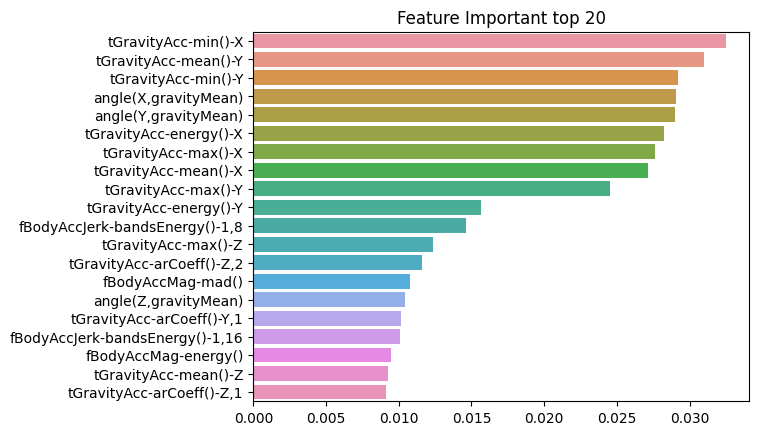

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index = X_train.columns)
ftr_top20 = ftr_importances.sort_values(ascending = False)[:20]

plt.Figure(figsize=(8,6)) 
plt.title("Feature Important top 20")
sns.barplot(x = ftr_top20, y= ftr_top20.index)
plt.show()
## 왜 무지개색이냐..?

In [15]:
from sklearn.ensemble import GradientBoostingClassifier
import time
X_train, X_test, y_train, y_test = get_human_dataset()

start_time =time.time()

gb_clf = GradientBoostingClassifier(random_state= 0 )
gb_clf.fit(X_train,y_train)
gb_pred = gb_clf.predict(X_test)
print(accuracy_score(y_test, gb_pred))
print(time.time() - start_time)

0.9389209365456397
509.812157869339


In [ ]:
#  경사 하강법 = ?? 



In [18]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators" : [100, 500],
    "learning_rate" : [0.05, 0.1]
}
grid_cv = GridSearchCV(gb_clf, param_grid = params, cv = 2 , verbose = 1)
grid_cv.fit(X_train,y_train)

print(grid_cv.best_params_)
print(grid_cv.best_score_)

Fitting 2 folds for each of 4 candidates, totalling 8 fits
{'learning_rate': 0.1, 'n_estimators': 500}
0.9017954298150164


In [ ]:
gb_pred = grid_cv.best_estimator